In [1]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju0s2a9ekvms080138tjjpxr.jpg"
GT_POLYP_MASK_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju0s2a9ekvms080138tjjpxr.jpg"
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.1.keras"

IMG_SIZE = (256, 256)

I0000 00:00:1787715464.478787   21916 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# --- rebuild architecture (needed to load this checkpoint, see last message) ---
def squeeze_and_excitation(x, ratio=16):
    f = x.shape[-1]
    s = tf.keras.layers.GlobalAveragePooling2D()(x)
    s = tf.keras.layers.Reshape((1, 1, f))(s)
    s = tf.keras.layers.Dense(f // ratio, activation="relu", use_bias=False)(s)
    s = tf.keras.layers.Dense(f, activation="sigmoid", use_bias=False)(s)
    return tf.keras.layers.Multiply()([x, s])

def _sp_shape(input_shape):
    return input_shape[:-1] + (1,)

def cbam_block(x, ratio=16):
    f = x.shape[-1]
    d1 = tf.keras.layers.Dense(f // ratio, activation="relu", use_bias=False)
    d2 = tf.keras.layers.Dense(f, use_bias=False)

    avg = tf.keras.layers.Reshape((1, 1, f))(tf.keras.layers.GlobalAveragePooling2D()(x))
    mx = tf.keras.layers.Reshape((1, 1, f))(tf.keras.layers.GlobalMaxPooling2D()(x))
    ch_att = tf.keras.layers.Activation("sigmoid")(
        tf.keras.layers.Add()([d2(d1(avg)), d2(d1(mx))])
    )
    x = tf.keras.layers.Multiply()([x, ch_att])

    avg_sp = tf.keras.layers.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True), output_shape=_sp_shape)(x)
    max_sp = tf.keras.layers.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True), output_shape=_sp_shape)(x)
    concat = tf.keras.layers.Concatenate(axis=-1)([avg_sp, max_sp])
    sp_att = tf.keras.layers.Conv2D(1, 7, padding="same", activation="sigmoid", use_bias=False)(concat)
    return tf.keras.layers.Multiply()([x, sp_att])

def se_encoder_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = squeeze_and_excitation(x)
    return x, tf.keras.layers.MaxPooling2D((2, 2))(x)

def cbam_decoder_block(x, skip, filters):
    x = tf.keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return cbam_block(x)

def build_dual_decoder_unet(input_shape=(256, 256, 3)):
    inputs = tf.keras.layers.Input(input_shape)
    s1, p1 = se_encoder_block(inputs, 64)
    s2, p2 = se_encoder_block(p1, 128)
    s3, p3 = se_encoder_block(p2, 256)
    s4, p4 = se_encoder_block(p3, 512)

    b1 = tf.keras.layers.Conv2D(1024, 3, padding="same")(p4)
    b1 = tf.keras.layers.BatchNormalization()(b1)
    b1 = tf.keras.layers.Activation("relu")(b1)
    b1 = tf.keras.layers.Conv2D(1024, 3, padding="same")(b1)
    b1 = tf.keras.layers.BatchNormalization()(b1)
    b1 = tf.keras.layers.Activation("relu")(b1)
    b1 = squeeze_and_excitation(b1)

    h = cbam_decoder_block(b1, s4, 512)
    h = cbam_decoder_block(h, s3, 256)
    h = cbam_decoder_block(h, s2, 128)
    h = cbam_decoder_block(h, s1, 64)
    healthy_output = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="healthy_output")(h)

    d = cbam_decoder_block(b1, s4, 512)
    d = cbam_decoder_block(d, s3, 256)
    d = cbam_decoder_block(d, s2, 128)
    d = cbam_decoder_block(d, s1, 64)
    polyp_output = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="polyp_output")(d)

    return tf.keras.models.Model(inputs, {"healthy_output": healthy_output, "polyp_output": polyp_output})

model = build_dual_decoder_unet()
model.load_weights(MODEL_PATH)

# --- warm-up: the FIRST predict() call triggers TF graph tracing/compilation,
# which is slow (several seconds to ~1 min). Doing it once here means every
# real predict() call afterwards (below, or on new images) is fast. ---
_ = model.predict(np.zeros((1, 256, 256, 3), dtype=np.float32), verbose=0)
print("Model ready.")

# --- OPTIONAL, run once: save a lightweight weights-only file so future
# notebook sessions load faster (skips re-parsing the full .keras archive).
# Uncomment the line below the first time, then switch back to
# model.load_weights(MODEL_PATH) above to MODEL_PATH = WEIGHTS_ONLY_PATH.
# WEIGHTS_ONLY_PATH = MODEL_PATH.replace(".keras", ".weights.h5")
# model.save_weights(WEIGHTS_ONLY_PATH)

W0000 00:00:1787715595.190938   21916 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1787715595.191225   21916 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
I0000 00:00:1787715769.385933   23325 service.cc:153] XLA service 0x7ad818051930 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787715769.385974   23325 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1787715769.542805   23325 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1787715770.282840   23325 cuda

Model ready.


In [5]:
# --- preprocessing (same as training: resize, CLAHE, sharpen, gaussian) ---
def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)

def apply_sharpen(img):
    k = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    return cv2.filter2D(img, -1, k)


def show_segmentation(image_path, gt_mask_path=None, img_size=IMG_SIZE):
    """Runs the model on one image and displays input / GT mask (optional) /
    predicted polyp mask / predicted healthy mask, side by side."""
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, img_size, interpolation=cv2.INTER_AREA)

    proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
    model_input = np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)

    preds = model.predict(model_input, verbose=0)
    healthy_pred = preds["healthy_output"][0, ..., 0]
    polyp_pred = preds["polyp_output"][0, ..., 0]

    gt_mask = None
    if gt_mask_path:
        gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
        gt_mask = cv2.resize(gt_mask, img_size, interpolation=cv2.INTER_NEAREST)

    n = 4 if gt_mask is not None else 3
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 5))

    axes[0].imshow(img)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    i = 1
    if gt_mask is not None:
        axes[i].imshow(gt_mask, cmap="gray")
        axes[i].set_title("Ground truth polyp mask")
        axes[i].axis("off")
        i += 1

    axes[i].imshow(polyp_pred, cmap="Reds")
    axes[i].set_title("Predicted polyp mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(healthy_pred, cmap="Greens")
    axes[i].set_title("Predicted healthy mask")
    axes[i].axis("off")

    plt.tight_layout()
    plt.show()

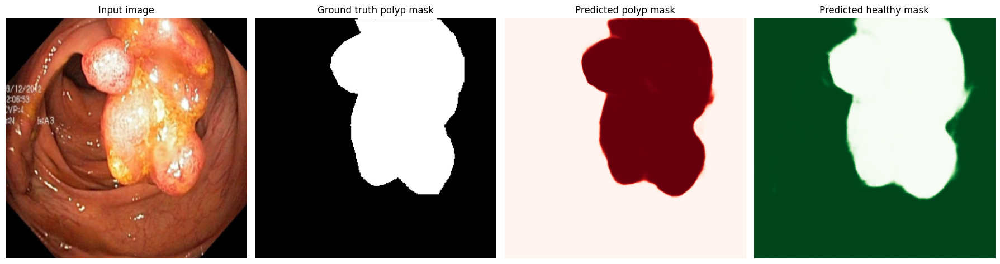

In [6]:
show_segmentation(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg",
)

In [10]:
# --- Grad-CAM for segmentation (Seg-Grad-CAM: target = sum of predicted mask) ---
def make_gradcam_heatmap(model, model_input, branch="polyp_output"):
    """branch: 'polyp_output' or 'healthy_output'.
    Targets the last decoder feature map (right before the final 1x1 conv)."""
    target_layer_output = model.get_layer(branch).input
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[target_layer_output, model.get_layer(branch).output],
    )

    with tf.GradientTape() as tape:
        conv_output, preds = grad_model(model_input)
        target_score = tf.reduce_sum(preds)  # scalar: total predicted mask "activation"

    grads = tape.gradient(target_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))  # (channels,)

    conv_output = conv_output[0]  # drop batch dim -> (H, W, C)
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(base_img_float, heatmap, img_size=IMG_SIZE, alpha=0.45):
    """base_img_float: HxWx3 in [0,1]. heatmap: small HxW in [0,1]."""
    heatmap_resized = cv2.resize(heatmap, img_size)
    heatmap_color = plt.cm.jet(heatmap_resized)[..., :3]  # RGB in [0,1]
    return np.clip((1 - alpha) * base_img_float + alpha * heatmap_color, 0, 1)
    
def show_gradcam(image_path, gt_mask_path=None, branch="polyp_output"):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

    proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
    model_input = tf.convert_to_tensor(
        np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)
    )

    preds = model.predict(model_input, verbose=0)
    polyp_pred = preds["polyp_output"][0, ..., 0]
    healthy_pred = preds["healthy_output"][0, ..., 0]

    gt_mask = None
    if gt_mask_path:
        gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
        gt_mask = cv2.resize(gt_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

    heatmap = make_gradcam_heatmap(model, model_input, branch=branch)

    # Overlay uses ONLY the polyp mask, colored like a heatmap (jet colormap,
    # intensity/alpha scaled by predicted probability) so it pops the way
    # a Grad-CAM-style overlay does, instead of a flat light color.
    MAX_ALPHA = 0.85
    MIN_PROB_TO_SHOW = 0.05  # keep background clean where confidence is near 0
    alpha_map = np.where(polyp_pred > MIN_PROB_TO_SHOW, polyp_pred * MAX_ALPHA, 0.0)
    polyp_heat_color = plt.cm.jet(polyp_pred)[..., :3]
    overlay = overlay_heatmap(img.astype(np.float32) / 255.0, heatmap)
    # overlay = np.clip(
    #     img.astype(np.float32) / 255.0 * (1 - alpha_map[..., None])
    #     + polyp_heat_color * alpha_map[..., None],
    #     0, 1,
    # )

    n = 6 if gt_mask is not None else 5
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 5))

    axes[0].imshow(img)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    i = 1
    if gt_mask is not None:
        axes[i].imshow(gt_mask, cmap="gray")
        axes[i].set_title("Ground truth polyp mask")
        axes[i].axis("off")
        i += 1

    axes[i].imshow(polyp_pred, cmap="Reds")
    axes[i].set_title("Predicted polyp mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(healthy_pred, cmap="Greens")
    axes[i].set_title("Predicted healthy mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(heatmap, cmap="jet")
    axes[i].set_title(f"Grad-CAM heatmap ({branch})")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(overlay)
    axes[i].set_title("Overlay (polyp only)")
    axes[i].axis("off")

    plt.tight_layout()
    plt.show()

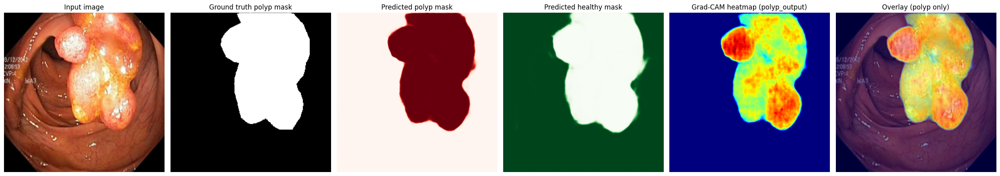

In [11]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg",
    branch="polyp_output",
)

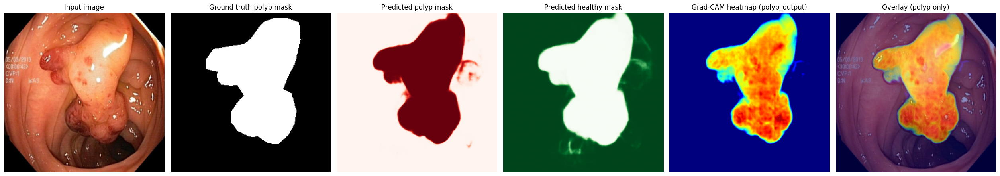

In [12]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34i3qvcyog0855qiejxx5w.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34i3qvcyog0855qiejxx5w.jpg",
    branch="polyp_output",
)

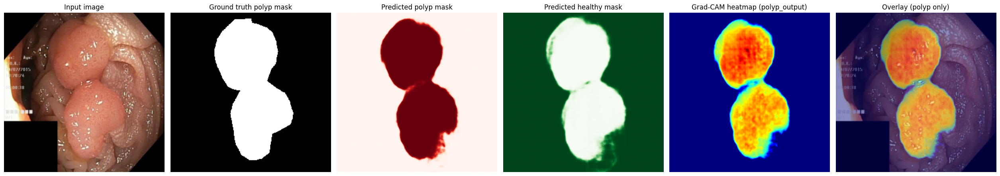

In [13]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34aozyyy830993bn16u32n.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34aozyyy830993bn16u32n.jpg",
    branch="polyp_output",
)

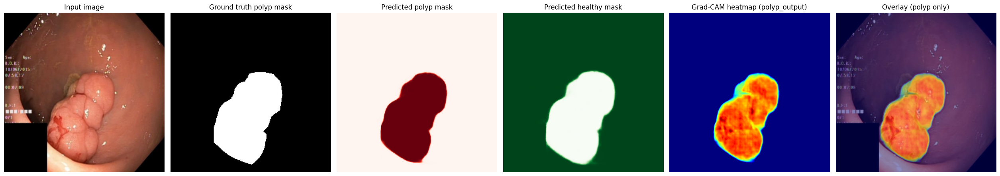

In [14]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju42dwedlmk60871jbgu4ehi.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju42dwedlmk60871jbgu4ehi.jpg",
    branch="polyp_output",
)

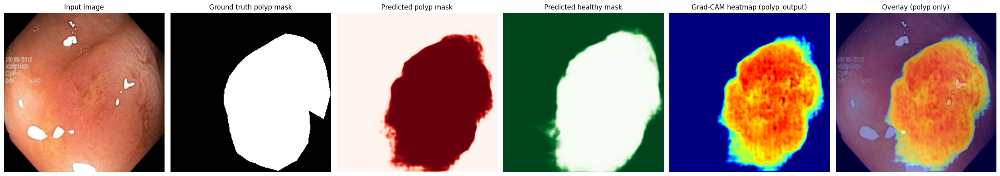

In [15]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju5knbbqfipk080128cggukq.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju5knbbqfipk080128cggukq.jpg",
    branch="polyp_output",
)

In [7]:
# --- Grad-CAM for segmentation (Seg-Grad-CAM: target = sum of predicted mask) ---
def make_gradcam_heatmap(model, model_input, branch="polyp_output"):
    """branch: 'polyp_output' or 'healthy_output'.
    Targets the last decoder feature map (right before the final 1x1 conv)."""
    target_layer_output = model.get_layer(branch).input
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[target_layer_output, model.get_layer(branch).output],
    )

    with tf.GradientTape() as tape:
        conv_output, preds = grad_model(model_input)
        target_score = tf.reduce_sum(preds)

    grads = tape.gradient(target_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(base_img_float, heatmap, img_size=IMG_SIZE, alpha=0.45):
    heatmap_resized = cv2.resize(heatmap, img_size)
    heatmap_color = plt.cm.jet(heatmap_resized)[..., :3]
    return np.clip((1 - alpha) * base_img_float + alpha * heatmap_color, 0, 1)


def show_gradcam(image_path, gt_mask_path=None, branch="polyp_output"):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

    proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
    model_input = tf.convert_to_tensor(
        np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)
    )

    preds = model.predict(model_input, verbose=0)
    polyp_pred = preds["polyp_output"][0, ..., 0]
    healthy_pred = preds["healthy_output"][0, ..., 0]

    gt_mask = None
    if gt_mask_path:
        gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
        gt_mask = cv2.resize(gt_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

    heatmap = make_gradcam_heatmap(model, model_input, branch=branch)

    MAX_ALPHA = 0.85
    MIN_PROB_TO_SHOW = 0.05
    alpha_map = np.where(polyp_pred > MIN_PROB_TO_SHOW, polyp_pred * MAX_ALPHA, 0.0)
    polyp_heat_color = plt.cm.jet(polyp_pred)[..., :3]
    overlay = overlay_heatmap(img.astype(np.float32) / 255.0, heatmap)

    n = 6 if gt_mask is not None else 5
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 5))

    axes[0].imshow(img)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    i = 1
    if gt_mask is not None:
        axes[i].imshow(gt_mask, cmap="gray")
        axes[i].set_title("Ground truth polyp mask")
        axes[i].axis("off")
        i += 1

    # NEW: polyp mask area shows the actual image, rest is solid green
    axes[i].imshow(np.where(
        (polyp_pred > 0.5)[..., None],
        img.astype(np.float32) / 255.0,
        np.array([0, 1, 0]),
    ))
    axes[i].set_title("Predicted Healthy Cells")
    axes[i].axis("off")
    i += 1

    # NEW: healthy mask area shows the actual image, rest (polyp) is solid red
    axes[i].imshow(np.where(
        (healthy_pred > 0.5)[..., None],
        img.astype(np.float32) / 255.0,
        np.array([1, 0, 0]),
    ))
    axes[i].set_title("Predicted Polyp")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(heatmap, cmap="jet")
    axes[i].set_title(f"Grad-CAM heatmap ({branch})")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(overlay)
    axes[i].set_title("Overlay (polyp only)")
    axes[i].axis("off")

    plt.tight_layout()
    plt.show()

# Kvasir-SEG

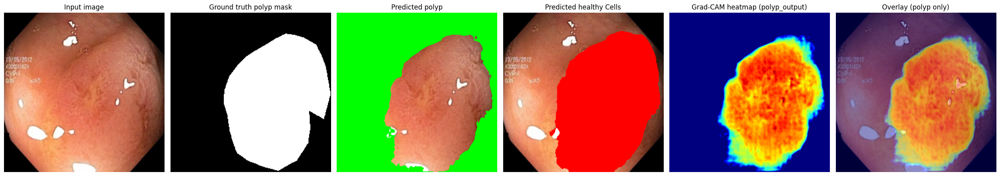

In [49]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju5knbbqfipk080128cggukq.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju5knbbqfipk080128cggukq.jpg",
    branch="polyp_output",
)

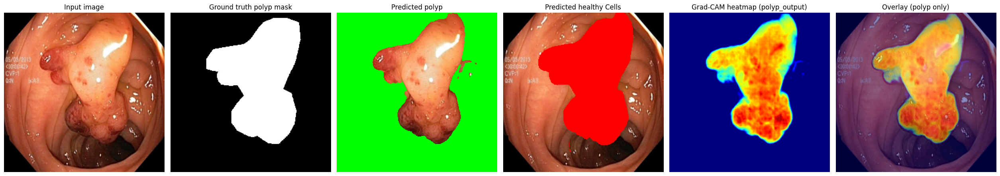

In [50]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34i3qvcyog0855qiejxx5w.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34i3qvcyog0855qiejxx5w.jpg",
    branch="polyp_output",
)

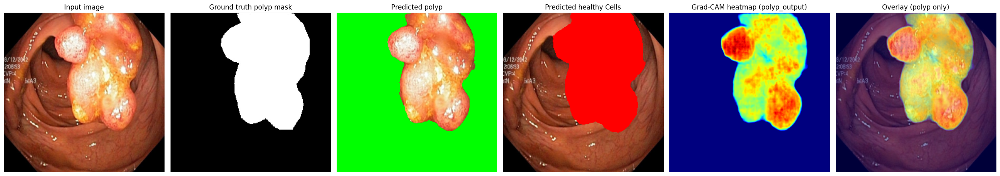

In [51]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg",
    branch="polyp_output",
)

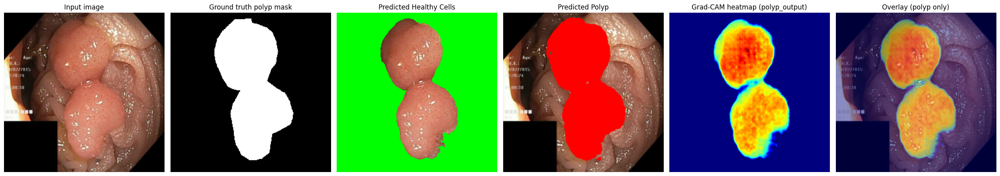

In [8]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34aozyyy830993bn16u32n.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34aozyyy830993bn16u32n.jpg",
    branch="polyp_output",
)

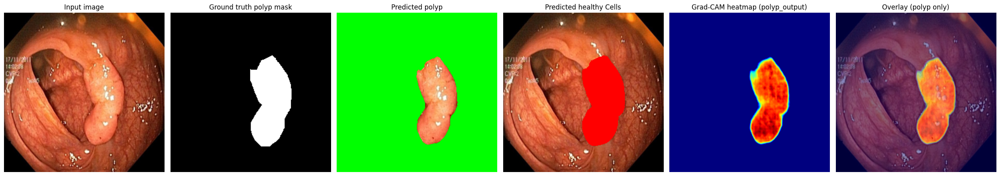

In [53]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2xa3i4y0160988i679zsqd.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2xa3i4y0160988i679zsqd.jpg",
    branch="polyp_output",
)

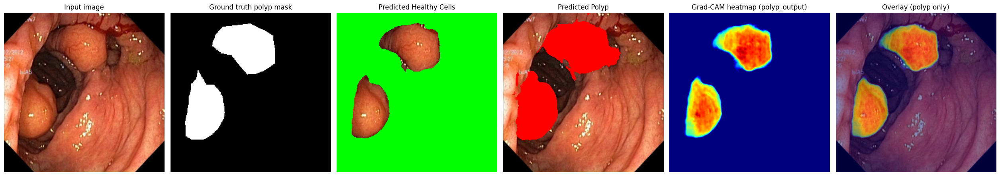

In [9]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju3v56bwgy8v0871w14pz8fx.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju3v56bwgy8v0871w14pz8fx.jpg",
    branch="polyp_output",
)

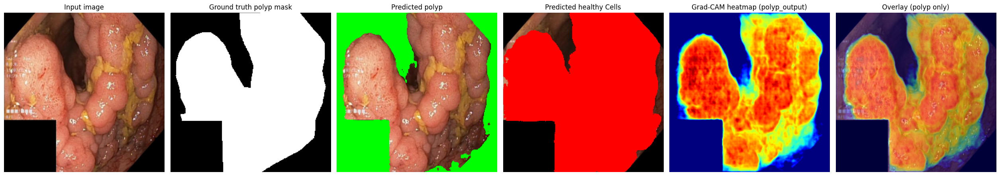

In [55]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju7eotqi2qea0871y8yc7tqh.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju7eotqi2qea0871y8yc7tqh.jpg",
    branch="polyp_output",
)

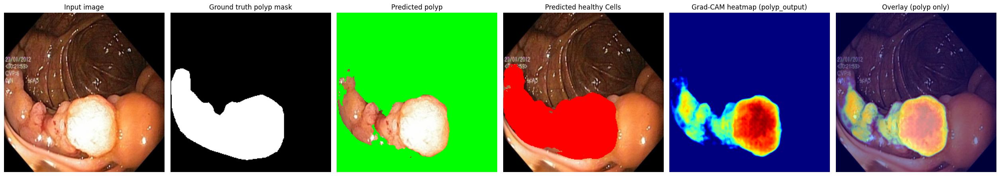

In [56]:

show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju175facms5f0993a5tjikvt.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju175facms5f0993a5tjikvt.jpg",
    branch="polyp_output",
)

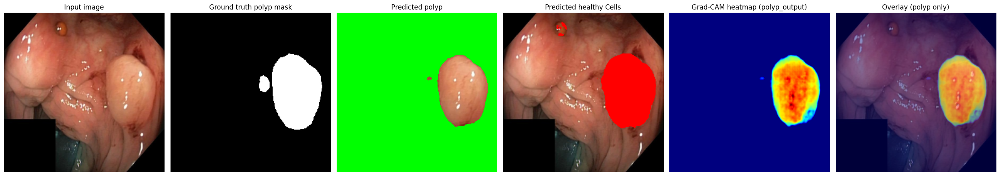

In [57]:

show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/ck2bxknhjvs1x0794iogrq49k.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/ck2bxknhjvs1x0794iogrq49k.jpg",
    branch="polyp_output",
)

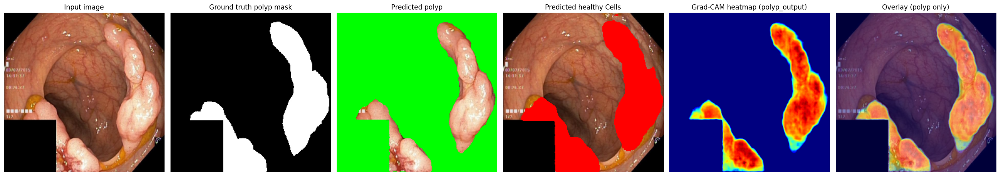

In [58]:


show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju430pm2lz0y0755jkhcc3d1.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju430pm2lz0y0755jkhcc3d1.jpg",
    branch="polyp_output",
)

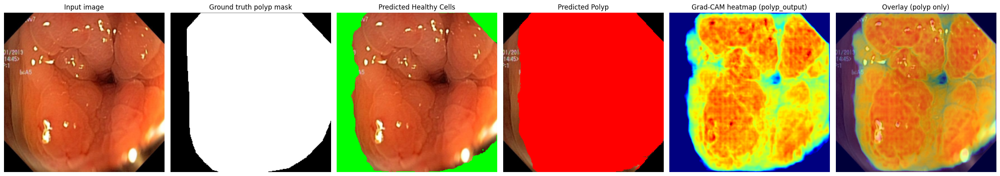

In [10]:

show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju88l66no10s0850rsda7ej1.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju88l66no10s0850rsda7ej1.jpg",
    branch="polyp_output",
)

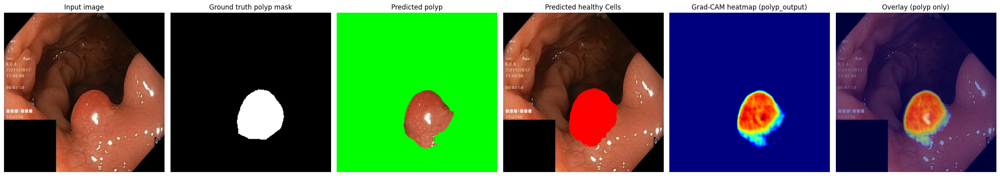

In [60]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju3xwpgviwlx0871rwm15q7v.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju3xwpgviwlx0871rwm15q7v.jpg",
    branch="polyp_output",
)

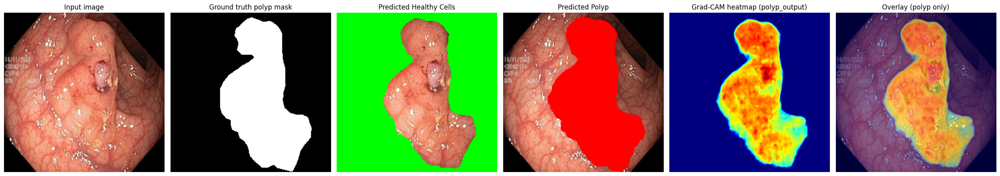

In [11]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju0qx73cjw570799j4n5cjze.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju0qx73cjw570799j4n5cjze.jpg",
    branch="polyp_output",
)

# PolypGen-TestSet

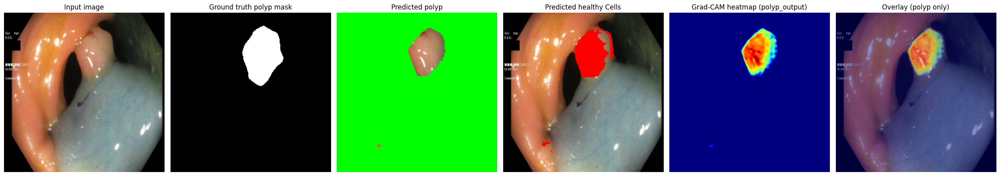

In [62]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001008.jpg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001008_mask.jpg",
    branch="polyp_output",
)

# ETIS-LaribPolypDB

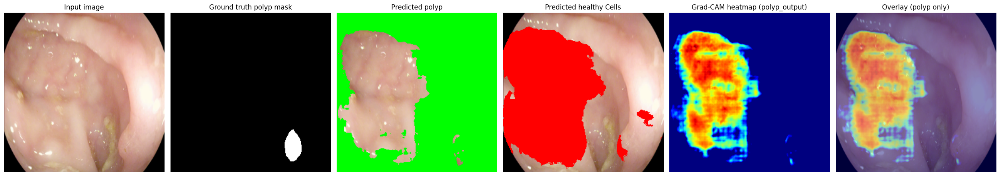

In [63]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/ETIS-LaribPolypDB/images/20.png",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/ETIS-LaribPolypDB/masks/20.png",
    branch="polyp_output",
)

# EndoTect

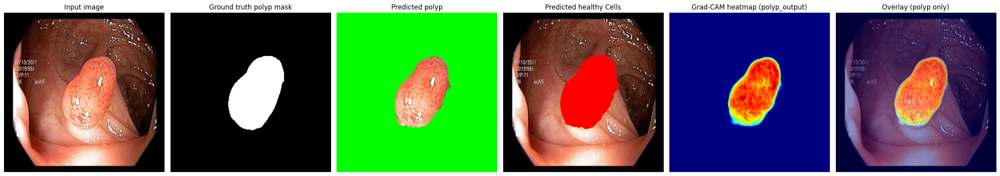

In [64]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/EndoTect/test_dataset/images/0f64a728-8a8a-430d-8584-e93ed71d8f8a.jpg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/EndoTect/test_dataset/masks/0f64a728-8a8a-430d-8584-e93ed71d8f8a.jpg",
    branch="polyp_output",
)

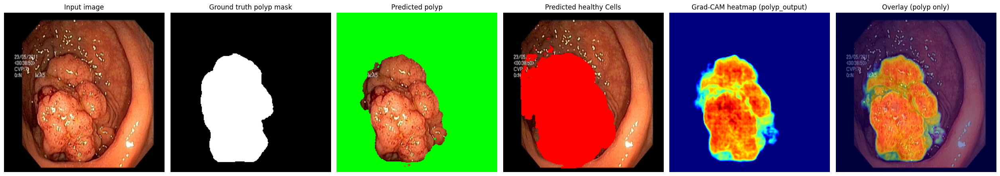

In [67]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/EndoTect/test_dataset/images/0a25da23-787f-47ce-877e-2934275b0801.jpg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/EndoTect/test_dataset/masks/0a25da23-787f-47ce-877e-2934275b0801.jpg",
    branch="polyp_output",
)

# CVC-ClinicDB

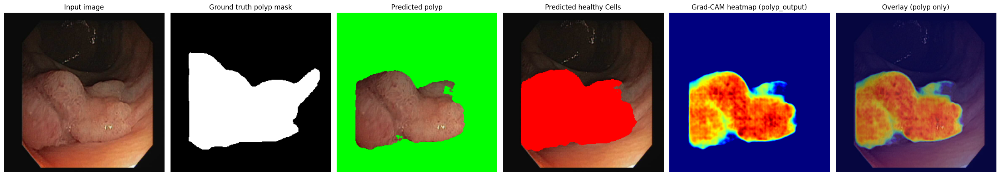

In [69]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG/images/272.png",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG/masks/272.png",
    branch="polyp_output",
)

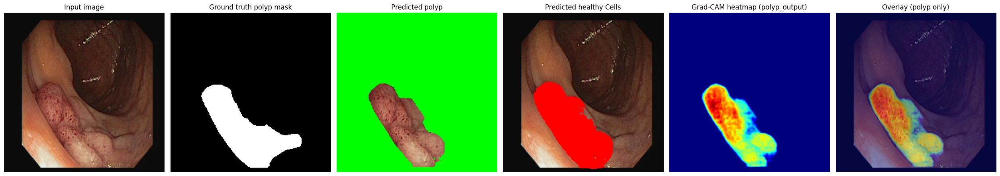

In [70]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG/images/277.png",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG/masks/277.png",
    branch="polyp_output",
)

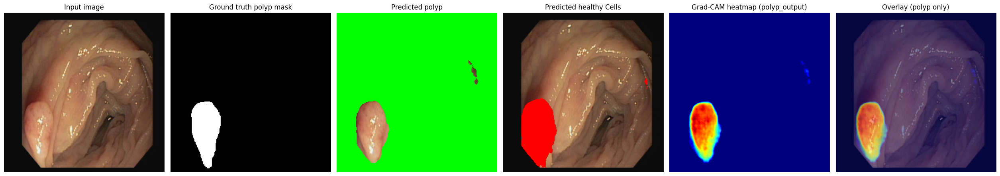

In [71]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG/images/440.png",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG/masks/440.png",
    branch="polyp_output",
)

# BKAI-IGH

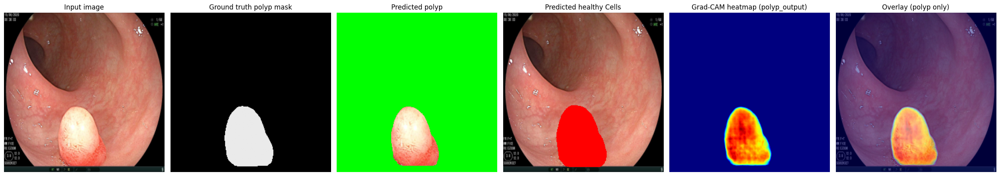

In [73]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train/train/01e80947f9c02314fc58bdb26679bff5.jpeg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train_gt/train_gt/01e80947f9c02314fc58bdb26679bff5.jpeg",
    branch="polyp_output",
)

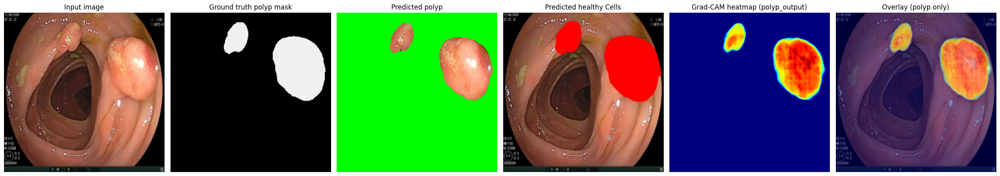

In [74]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train/train/1d4dc3ddad260bfcb4443de3ef69f6db.jpeg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train_gt/train_gt/1d4dc3ddad260bfcb4443de3ef69f6db.jpeg",
    branch="polyp_output",
)

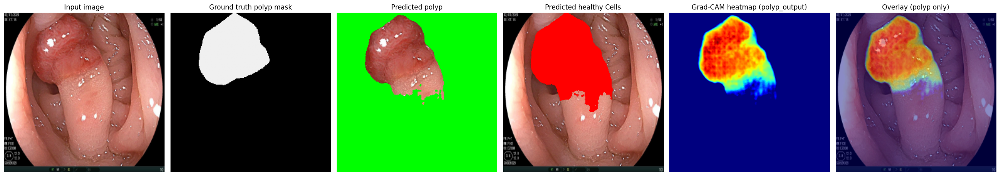

In [78]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train/train/2345d341253851bc866ebe4d18d5401f.jpeg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train_gt/train_gt/2345d341253851bc866ebe4d18d5401f.jpeg",
    branch="polyp_output",
)

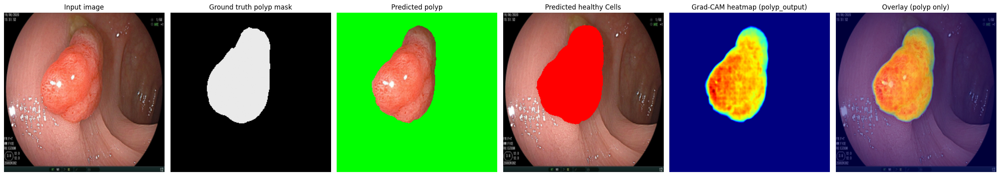

In [79]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train/train/f7f8a4df1ec859759b7c8743c61a01e8.jpeg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train_gt/train_gt/f7f8a4df1ec859759b7c8743c61a01e8.jpeg",
    branch="polyp_output",
)

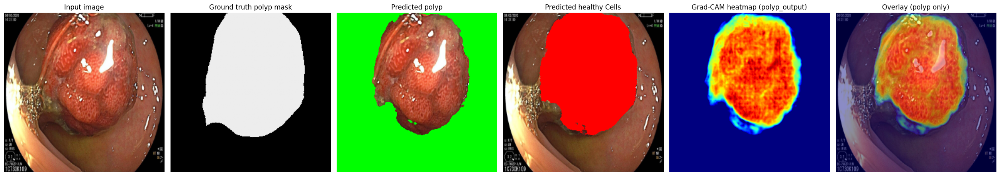

In [80]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train/train/cd771e7606cb09d1fc6869d7b4193425.jpeg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train_gt/train_gt/cd771e7606cb09d1fc6869d7b4193425.jpeg",
    branch="polyp_output",
)

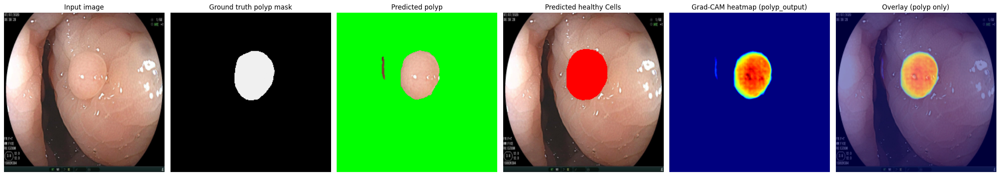

In [81]:
show_gradcam(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train/train/aa982e29fb841ad9698b3cb63f254f6b.jpeg",
     "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/bkai-igh-neopolyp/train_gt/train_gt/aa982e29fb841ad9698b3cb63f254f6b.jpeg",
    branch="polyp_output",
)

In [13]:
import cv2
import numpy as np
import glob

def combine_images_with_header(
    image_paths, 
    output_path="combined_output.png", 
    cols=2, 
    header_text="Kvasir-SEG test set"
):
    # 1. Load images
    images = [cv2.imread(p) for p in image_paths]
    images = [img for img in images if img is not None]

    if not images:
        print("Error: No valid images found.")
        return

    # 2. Resize all images to match the dimensions of the first image
    target_h, target_w = images[0].shape[:2]
    resized_images = [cv2.resize(img, (target_w, target_h)) for img in images]

    # 3. Calculate grid dimensions (rows and columns)
    num_images = len(resized_images)
    rows = int(np.ceil(num_images / cols))

    # Pad empty grid slots with white background if grid is incomplete
    blank_cell = np.ones((target_h, target_w, 3), dtype=np.uint8) * 255
    while len(resized_images) < rows * cols:
        resized_images.append(blank_cell)

    # 4. Concatenate images into grid
    row_images = []
    for i in range(rows):
        row_concat = np.hstack(resized_images[i * cols : (i + 1) * cols])
        row_images.append(row_concat)
    
    grid_img = np.vstack(row_images)
    grid_h, grid_w = grid_img.shape[:2]

    # 5. Create header banner at the top
    header_h = max(60, int(grid_h * 0.08))  # Dynamic header height
    header_bg = np.ones((header_h, grid_w, 3), dtype=np.uint8) * 255  # White banner

    # 6. Calculate text position to center it dynamically
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = max(0.8, grid_w / 800.0)  # Dynamic font size based on image width
    thickness = max(2, int(font_scale * 2))

    (text_w, text_h), baseline = cv2.getTextSize(header_text, font, font_scale, thickness)
    text_x = int((grid_w - text_w) / 2)
    text_y = int((header_h + text_h) / 2)

    # Draw centered header text (Black)
    cv2.putText(
        header_bg, 
        header_text, 
        (text_x, text_y), 
        font, 
        font_scale, 
        (0, 0, 0), 
        thickness, 
        cv2.LINE_AA
    )

    # 7. Combine header and grid vertically
    final_frame = np.vstack([header_bg, grid_img])

    # 8. Save result
    cv2.imwrite(output_path, final_frame)
    print(f"Successfully saved combined frame to: {output_path}")

# --- Example Usage ---
# Replace with your actual image paths or use glob to get all matching files
image_files = [
    "./img-1.png",
    "./img-2.png",
    "./img-3.png",
    "./img-5.png",
    "./img-6.png",
    "./img-7.png"
]

# Set cols=1 for a single vertical stack, cols=2 for 2-column grid, etc.
combine_images_with_header(image_files, output_path="kvasir_xai_grid.png", cols=2)

Successfully saved combined frame to: kvasir_xai_grid.png


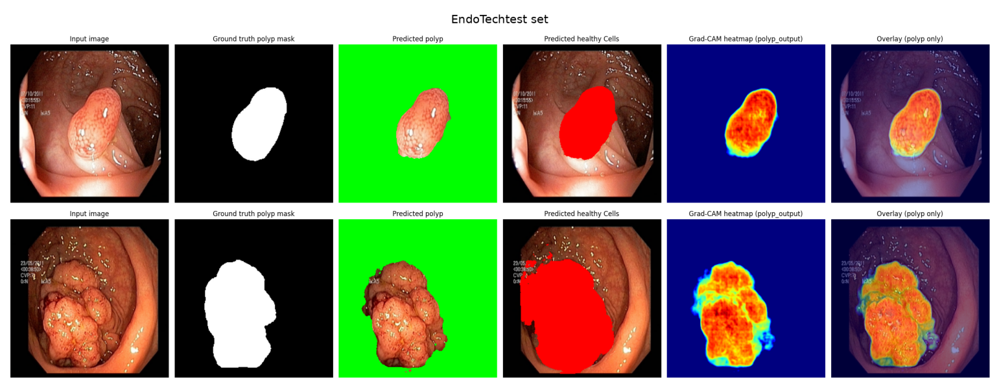

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

def combine_and_show_images(
    image_paths, 
    cols=1, 
    header_text="EndoTechtest set"
):
    # 1. Load images
    images = [cv2.imread(p) for p in image_paths]
    images = [img for img in images if img is not None]

    if not images:
        print("Error: No valid images found.")
        return

    # 2. Resize all images to match the dimensions of the first image
    target_h, target_w = images[0].shape[:2]
    resized_images = [cv2.resize(img, (target_w, target_h)) for img in images]

    # 3. Concatenate images vertically (cols=1) or into a grid
    num_images = len(resized_images)
    rows = int(np.ceil(num_images / cols))

    blank_cell = np.ones((target_h, target_w, 3), dtype=np.uint8) * 255
    while len(resized_images) < rows * cols:
        resized_images.append(blank_cell)

    row_images = []
    for i in range(rows):
        row_concat = np.hstack(resized_images[i * cols : (i + 1) * cols])
        row_images.append(row_concat)
    
    grid_img = np.vstack(row_images)
    grid_h, grid_w = grid_img.shape[:2]

    # 4. Proportional header height based on single cell width
    header_h = max(60, int(target_h * 0.15))
    header_bg = np.ones((header_h, grid_w, 3), dtype=np.uint8) * 255  # White header banner

    # 5. Convert header to PIL Image for high-quality, crisp text rendering
    pil_header = Image.fromarray(header_bg)
    draw = ImageDraw.Draw(pil_header)

    # Load system font or fall back to default PIL font
    font_size = max(18, int(header_h * 0.45))
    try:
        font = ImageFont.truetype("arial.ttf", font_size)
    except IOError:
        try:
            font = ImageFont.truetype("DejaVuSans.ttf", font_size)
        except IOError:
            font = ImageFont.load_default()

    # Calculate exact text bounding box for dead-center positioning
    bbox = draw.textbbox((0, 0), header_text, font=font)
    text_w = bbox[2] - bbox[0]
    text_h = bbox[3] - bbox[1]

    text_x = (grid_w - text_w) // 2
    text_y = (header_h - text_h) // 2 - bbox[1]  # Compensate for font top-padding

    # Draw sharp text
    draw.text((text_x, text_y), header_text, fill=(0, 0, 0), font=font)
    header_bg = np.array(pil_header)

    # 6. Combine header and image grid
    final_frame = np.vstack([header_bg, grid_img])

    # 7. Convert BGR to RGB for Matplotlib
    final_frame_rgb = cv2.cvtColor(final_frame, cv2.COLOR_BGR2RGB)

    # 8. Render figure with proportional aspect ratio
    aspect_ratio = final_frame_rgb.shape[0] / final_frame_rgb.shape[1]
    fig_w = 16
    fig_h = fig_w * aspect_ratio

    plt.figure(figsize=(fig_w, min(fig_h, 20)))  # Cap height at 20 to fit screen
    plt.imshow(final_frame_rgb)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# --- Example Usage ---
image_files = [
  "./endo-1.png",
    "./endo-2.png"
]

combine_and_show_images(image_files, cols=1)